# Inspect the fitted four-stock SDE-GAN

Load the selected checkpoints without retraining, compare solver steps **0.25**
and **0.125** using coupled randomness, and inspect volatility and generated
returns. Select the existing `sandbox/.venv` interpreter as your notebook kernel.
Run all cells from the repository root or this notebook's directory.

These are unconditional scenarios, not predictions for particular future dates.
The saved generator was trained on **20 trading-session paths**. The plots use
that supported horizon; extending to 30 sessions requires an explicit
extrapolation design. Market sessions are not calendar days.

Only training and validation observations are examined here. The test split
remains reserved for evaluation after model choices have been frozen.

In [1]:
from pathlib import Path
from dataclasses import replace, asdict
import json
import os
import sys

os.environ["JAX_PLATFORMS"] = "cpu"  # Restart the kernel if JAX already initialized elsewhere.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "sandbox/4stocks_experiment/sde_gan.py").is_file())
experiment_dir = root / "sandbox/4stocks_experiment"
sys.path.insert(0, str(experiment_dir)) if str(experiment_dir) not in sys.path else None
from sde_gan import SDEGAN

RUN_SEEDS = [0, 1, 2]
PLOT_SEED = 0  # Chosen in advance, not the run with the most attractive plots.
N_PATHS = 1000
SAMPLE_SEED = 100
BOOTSTRAP_REPEATS = 300
BOOTSTRAP_SEED = 2026
COARSE_DT = 0.25
FINE_DT = 0.125
out_dir = experiment_dir / "results/sde_gan/inspection"
out_dir.mkdir(parents=True, exist_ok=True)
models, metadata, selected = {}, {}, []
for seed in RUN_SEEDS:
    run_dir = experiment_dir / "results/sde_gan" / f"seed_{seed}"
    models[seed] = SDEGAN.load(run_dir)
    metadata[seed] = json.loads((run_dir / "preprocessing.json").read_text())
    selected.append({"seed": seed, **models[seed].run_metadata})
reference_metadata = metadata[RUN_SEEDS[0]]
if any(m != reference_metadata for m in metadata.values()):
    raise ValueError("Runs use different preprocessing; compare matching data separately")
STOCKS = reference_metadata["stock_order"]
display(pd.DataFrame(selected).set_index("seed")[["selected_step", "validation_score", "kernel_bandwidth"]])
print(f"Python: {sys.executable}; {N_PATHS} paths per seed and solver step")

Matplotlib is building the font cache; this may take a moment.


,selected_step,validation_score,kernel_bandwidth
seed,,,
0,1600,0.018549,11.425713
1,2000,0.018292,11.425713
2,2000,0.019369,11.425713


Python: /Users/pasha/Desktop/master/master_thesis/sandbox/.venv/bin/python; 1000 paths per seed and solver step


## Restore original units and observed windows

Invert each generator's saved scaler, then apply `expm1` to obtain simple returns.
Observed windows come directly from CSV values, preserving exact zero returns.
Use the same complete, 20-session windows retained during preprocessing so the
comparison matches the distribution used to train the model. Overlap repeats
some observed dates; this is not a sample of independent market episodes.

In [2]:
def to_simple(paths: np.ndarray, meta: dict) -> np.ndarray:
    """Invert the saved scaler without changing the generated trajectories."""
    if paths.ndim != 3 or paths.shape[1:] != (20, 4) or not np.isfinite(paths).all():
        raise ValueError("Expected finite standardized paths with shape (n, 20, 4)")
    with np.errstate(over="raise", invalid="raise"):
        result = np.expm1(paths.astype(np.float64) * np.asarray(meta["training_std"])
                          + np.asarray(meta["training_mean"]))
    if not np.isfinite(result).all():
        raise ValueError("Nonfinite simple returns")
    return result


def observed_windows(split: str) -> np.ndarray:
    """Load original simple-return windows without bridging missing sessions."""
    frame = pd.read_csv(experiment_dir / "data" / f"{split}_returns.csv",
                        index_col="Date", parse_dates=["Date"]).loc[:, STOCKS]
    if not frame.index.is_unique or not frame.index.is_monotonic_increasing:
        raise ValueError(f"{split}: invalid date index")
    dates = pd.read_csv(experiment_dir / "data/window_dates.csv",
                        parse_dates=["start_date", "end_date"])
    dates = dates.loc[dates.split.eq(split)].sort_values("window_index")
    paths = np.stack([frame.loc[row.start_date:row.end_date].to_numpy()
                      for row in dates.itertuples()])
    if paths.shape[1:] != (20, 4) or not np.isfinite(paths).all():
        raise ValueError(f"{split}: incomplete observed windows")
    # Check that current CSVs and window dates still match the saved prepared data.
    with np.load(experiment_dir / "data/prepared_windows.npz", allow_pickle=False) as prepared:
        np.testing.assert_allclose(to_simple(prepared[f"{split}_windows"], reference_metadata),
                                   paths, rtol=1e-6, atol=1e-7)
    if len(paths) != reference_metadata["splits"][split]["retained"]:
        raise ValueError("Observed windows differ from checkpoint metadata")
    return paths


observed = {split: observed_windows(split) for split in ["train", "validation"]}
print("Observed shapes:", {k: v.shape for k, v in observed.items()})

Observed shapes: {'train': (1679, 20, 4), 'validation': (709, 20, 4)}


## Generate coupled coarse and fine samples

For each checkpoint, keep all weights, the initial noise, Brownian-tree tolerance,
and sampling seeds unchanged. Change only the integration step. The model ties
random keys to path indices; its Brownian tree has identical bounds, tolerance,
and seed at both steps, so each coarse/fine pair uses the same Brownian
realization. This makes solver differences easier to detect than unrelated draws.
Both solves retain the original 20 observation times and horizon.

The config override exists only in memory. No checkpoint is saved or changed.
Check that initial observations match exactly, and that the loaded fine solver
reproduces its first 17 paths when requested again.

In [3]:
coarse_simple, fine_simple, path_errors = {}, {}, []
for seed, model in models.items():
    if not np.isclose(model.config.generator_dt, COARSE_DT):
        raise ValueError("This comparison expects a checkpoint trained with step 0.25")
    fine = SDEGAN.load(experiment_dir / "results/sde_gan" / f"seed_{seed}")
    fine.config = replace(fine.config, generator_dt=FINE_DT)
    coarse_config, fine_config = asdict(model.config), asdict(fine.config)
    assert [k for k in coarse_config if coarse_config[k] != fine_config[k]] == ["generator_dt"]
    print(f"Sampling seed {seed}: steps {COARSE_DT} and {FINE_DT}", flush=True)
    coarse = model.sample(n_paths=N_PATHS, seed=SAMPLE_SEED)
    refined = fine.sample(n_paths=N_PATHS, seed=SAMPLE_SEED)
    np.testing.assert_array_equal(coarse[:, 0], refined[:, 0])
    np.testing.assert_array_equal(refined[:17], fine.sample(n_paths=17, seed=SAMPLE_SEED))
    coarse_simple[seed] = to_simple(coarse, metadata[seed])
    fine_simple[seed] = to_simple(refined, metadata[seed])
    path_errors.append({"seed": seed, **dict(zip(STOCKS,
        np.sqrt(np.mean((fine_simple[seed] - coarse_simple[seed])**2, axis=(0, 1))) * 100))})
    np.savez_compressed(out_dir / f"samples_seed_{seed}.npz",
                        coarse_standardized_log=coarse, fine_standardized_log=refined)
path_errors = pd.DataFrame(path_errors).set_index("seed")
print("Paired daily-return RMSE (percentage points):")
display(path_errors)

Sampling seed 0: steps 0.25 and 0.125


Sampling seed 1: steps 0.25 and 0.125


Sampling seed 2: steps 0.25 and 0.125


Paired daily-return RMSE (percentage points):


,KONGSBERG GRUPPEN,FRONTLINE,WILH Wilhelmsen B,TOMRA SYSTEMS
seed,,,,
0,0.11231,0.263770,0.144360,0.094234
1,0.06933,0.150568,0.064848,0.081083
2,0.10736,0.151182,0.062914,0.063654


## Compare step changes with sampling uncertainty

Compare marginal mean returns, daily volatility, and the 5% quantile of terminal
returns for an equal-weight portfolio rebalanced each session. These quantities
are expressed in **percentage points**. Positive differences mean fine minus coarse.

Bootstrap complete generated paths, using the same resampled indices for each
coarse/fine pair. This preserves dependence within a path. `coarse_mc_se_pp`
estimates sampling variability of the coarse statistic; `paired_delta_*` gives
an approximate 95% bootstrap interval for the step difference. These measure
Monte Carlo variability for this fitted model, not uncertainty in the fitted
weights or the observed market distribution.

`larger_than_mc95` flags changes exceeding approximately 1.96 coarse sampling
standard errors. It is a review heuristic, not a formal multiple-testing procedure
or proof of convergence. If changes are material, investigate a further refinement
(for example 0.0625 with a smaller, shared Brownian tolerance). Small changes here
support these particular summaries, not every tail or dependence property.

In [4]:
def summary_vector(simple: np.ndarray) -> np.ndarray:
    """Summarize moments and exact compounded simple portfolio returns."""
    flat = simple.reshape(-1, 4)
    portfolio_terminal = np.prod(1 + simple.mean(axis=2), axis=1) - 1
    return np.r_[flat.mean(axis=0), flat.std(axis=0, ddof=1),
                 np.quantile(portfolio_terminal, 0.05)] * 100


metric_names = [f"mean: {s}" for s in STOCKS] + [f"daily_std: {s}" for s in STOCKS] + ["portfolio_terminal_q05"]
sensitivity_tables = []
for seed in RUN_SEEDS:
    a, b = coarse_simple[seed], fine_simple[seed]
    rng = np.random.default_rng(BOOTSTRAP_SEED)
    coarse_boot, delta_boot = [], []
    for _ in range(BOOTSTRAP_REPEATS):
        indices = rng.integers(0, len(a), size=len(a))
        av = summary_vector(a[indices])
        coarse_boot.append(av)
        delta_boot.append(summary_vector(b[indices]) - av)
    av, bv = summary_vector(a), summary_vector(b)
    se = np.std(coarse_boot, axis=0, ddof=1)
    interval = np.quantile(delta_boot, [0.025, 0.975], axis=0)
    table = pd.DataFrame({"seed": seed, "metric": metric_names,
        "coarse_pp": av, "fine_pp": bv, "difference_pp": bv-av,
        "coarse_mc_se_pp": se, "paired_delta_lower_pp": interval[0],
        "paired_delta_upper_pp": interval[1],
        "larger_than_mc95": np.abs(bv-av) > 1.96 * se})
    sensitivity_tables.append(table)
sensitivity = pd.concat(sensitivity_tables, ignore_index=True).set_index(["seed", "metric"])
sensitivity.to_csv(out_dir / "solver_sensitivity.csv")
display(sensitivity.round(6))
print(f"{int(sensitivity.larger_than_mc95.sum())} of {len(sensitivity)} summary changes exceed the MC review heuristic.")
print("Review magnitudes and the paired path plots; no manual sensitivity flag is changed.")
# Independent arithmetic check for portfolio compounding and metric units.
fixture = np.zeros((2, 20, 4))
fixture[:, 0, 0] = 0.10
np.testing.assert_allclose(summary_vector(fixture)[-1], 2.5)

coarse_pp    fine_pp  difference_pp  \
seed metric                                                              
0    mean: KONGSBERG GRUPPEN        0.107788   0.098157      -0.009631   
     mean: FRONTLINE                0.216440   0.205545      -0.010894   
     mean: WILH Wilhelmsen B       -0.019683  -0.029581      -0.009898   
     mean: TOMRA SYSTEMS            0.008031   0.004874      -0.003157   
     daily_std: KONGSBERG GRUPPEN   1.857964   1.857856      -0.000108   
     daily_std: FRONTLINE           4.090023   4.090982       0.000959   
     daily_std: WILH Wilhelmsen B   1.943915   1.945030       0.001115   
     daily_std: TOMRA SYSTEMS       1.314964   1.316227       0.001263   
     portfolio_terminal_q05       -20.865859 -20.793078       0.072782   
1    mean: KONGSBERG GRUPPEN        0.024406   0.025252       0.000846   
     mean: FRONTLINE               -0.136789  -0.133574       0.003216   
     mean: WILH Wilhelmsen B        0.119414   0.117540      -0.001874   
     mean: TOMRA SYSTEMS            0.336069   0.327828      -0.008242   
     daily_std: KONGSBERG GRUPPEN   1.673127   1.671296      -0.001831   
     daily_std: FRONTLINE           3.239668   3.237712      -0.001956   
     daily_std: WILH Wilhelmsen B   1.973974   1.974521       0.000547   
     daily_std: TOMRA SYSTEMS       2.025076   2.021721      -0.003355   
     portfolio_terminal_q05       -16.212269 -16.291476      -0.079207   
2    mean: KONGSBERG GRUPPEN        0.027447   0.031754       0.004307   
     mean: FRONTLINE                0.308541   0.304163      -0.004378   
     mean: WILH Wilhelmsen B       -0.133183  -0.139469      -0.006285   
     mean: TOMRA SYSTEMS            0.319507   0.316342      -0.003165   
     daily_std: KONGSBERG GRUPPEN   1.864330   1.866768       0.002438   
     daily_std: FRONTLINE           3.231196   3.231168      -0.000028   
     daily_std: WILH Wilhelmsen B   1.386290   1.387136       0.000846   
     daily_std: TOMRA SYSTEMS       1.767324   1.768597       0.001273   
     portfolio_terminal_q05       -10.866898 -10.959736      -0.092838   

                                   coarse_mc_se_pp  paired_delta_lower_pp  \
seed metric                                                                 
0    mean: KONGSBERG GRUPPEN              0.027768              -0.013394   
     mean: FRONTLINE                      0.090922              -0.021528   
     mean: WILH Wilhelmsen B              0.038074              -0.015944   
     mean: TOMRA SYSTEMS                  0.023165              -0.006635   
     daily_std: KONGSBERG GRUPPEN         0.029805              -0.004334   
     daily_std: FRONTLINE                 0.100121              -0.013295   
     daily_std: WILH Wilhelmsen B         0.033623              -0.006925   
     daily_std: TOMRA SYSTEMS             0.019547              -0.001737   
     portfolio_terminal_q05               0.637837              -0.628179   
1    mean: KONGSBERG GRUPPEN              0.031466              -0.001532   
     mean: FRONTLINE                      0.065133              -0.002503   
     mean: WILH Wilhelmsen B              0.037075              -0.004004   
     mean: TOMRA SYSTEMS                  0.031410              -0.010850   
     daily_std: KONGSBERG GRUPPEN         0.021116              -0.004211   
     daily_std: FRONTLINE                 0.049825              -0.007380   
     daily_std: WILH Wilhelmsen B         0.023636              -0.001681   
     daily_std: TOMRA SYSTEMS             0.028606              -0.005289   
     portfolio_terminal_q05               0.568272              -0.422222   
2    mean: KONGSBERG GRUPPEN              0.037687               0.000047   
     mean: FRONTLINE                      0.049852              -0.011531   
     mean: WILH Wilhelmsen B              0.029475              -0.009295   
     mean: TOMRA SYSTEMS                  0.033177              -0.005491   
     daily_std: KONGSBERG GRUPPEN       

0 of 27 summary changes exceed the MC review heuristic.
Review magnitudes and the paired path plots; no manual sensitivity flag is changed.


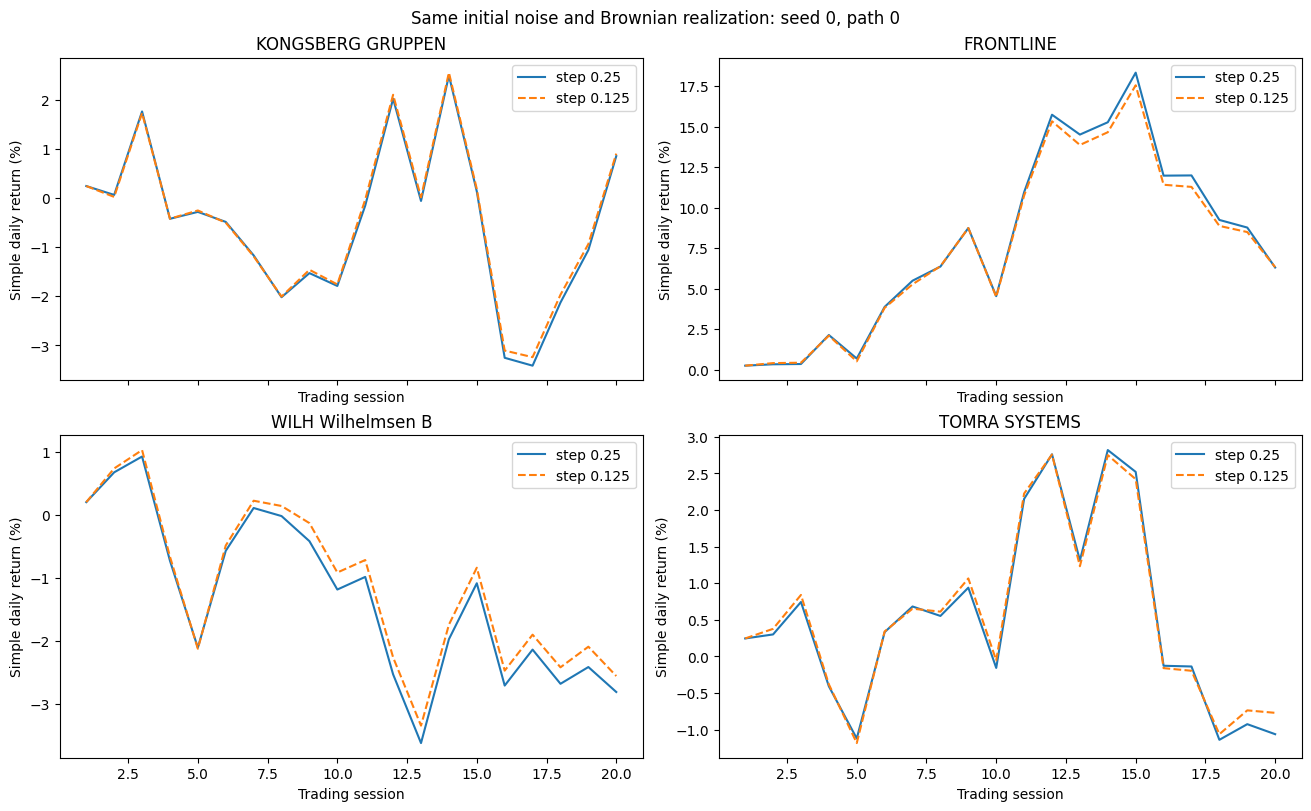

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, constrained_layout=True)
for j, ax in enumerate(axes.flat):
    ax.plot(np.arange(1, 21), coarse_simple[PLOT_SEED][0, :, j] * 100, label="step 0.25")
    ax.plot(np.arange(1, 21), fine_simple[PLOT_SEED][0, :, j] * 100, "--", label="step 0.125")
    ax.set(title=STOCKS[j], xlabel="Trading session", ylabel="Simple daily return (%)")
    ax.legend()
fig.suptitle(f"Same initial noise and Brownian realization: seed {PLOT_SEED}, path 0")
fig.savefig(out_dir / "coupled_solver_paths.png", dpi=150)
plt.show()
plt.close(fig)

## Volatility compared with observed returns

Daily volatility is the sample standard deviation of simple daily returns,
reported in percent per session, with no annualization. Compare both training
and validation data: the generator learned the training regime mixture, and
validation may have different volatility. These are window-weighted comparisons.
Also examine the distribution of within-window sample volatility, which can
reveal variation hidden by a single pooled number. Observed overlapping windows
are descriptive, not independent observations for a significance test.

,KONGSBERG GRUPPEN,FRONTLINE,WILH Wilhelmsen B,TOMRA SYSTEMS
dataset,,,,
train,1.809,3.642,1.794,1.893
validation,1.988,3.597,2.387,2.392
generated seed 0,1.858,4.090,1.944,1.315
generated seed 1,1.673,3.240,1.974,2.025
generated seed 2,1.864,3.231,1.386,1.767


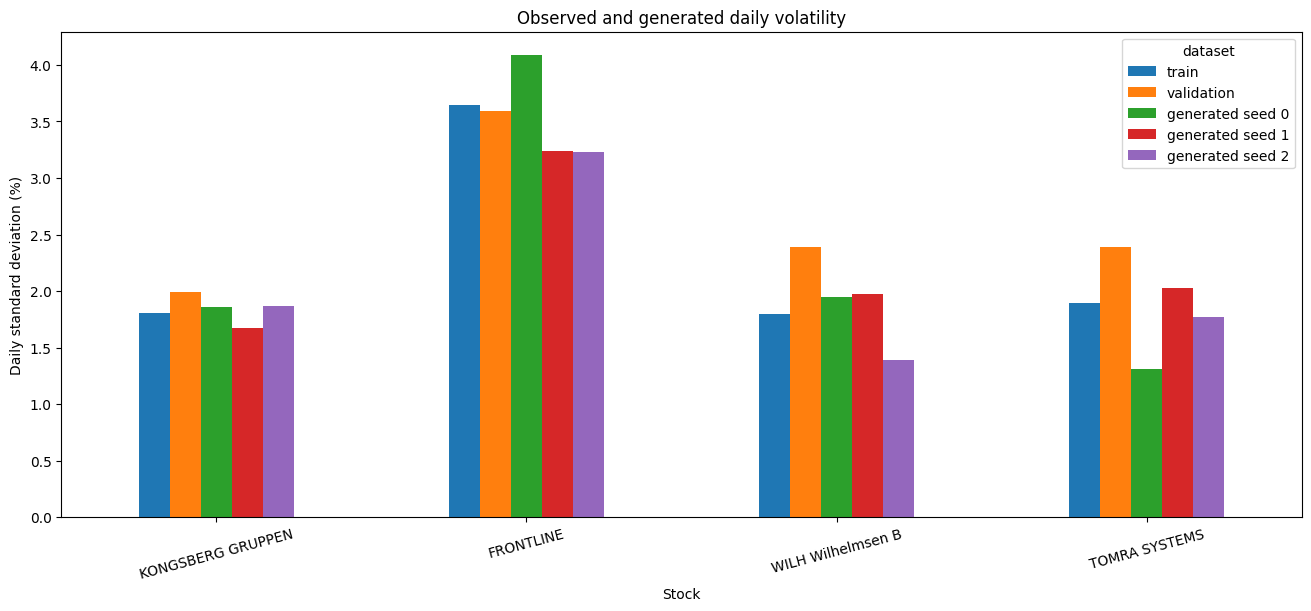

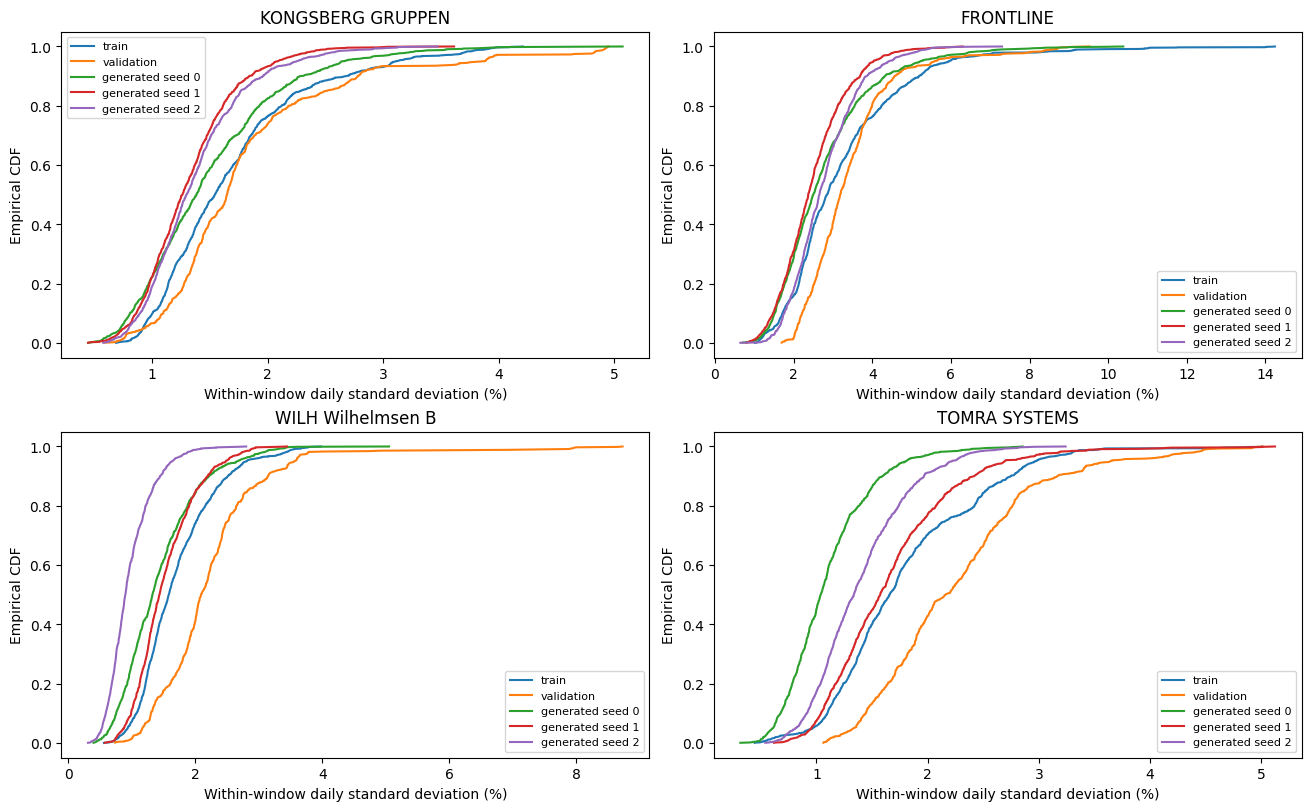

In [6]:
datasets = {**observed, **{f"generated seed {s}": a for s, a in coarse_simple.items()}}
volatility = pd.DataFrame({name: a.reshape(-1, 4).std(axis=0, ddof=1) * 100
                           for name, a in datasets.items()}, index=STOCKS).T
volatility.index.name = "dataset"
volatility.to_csv(out_dir / "daily_volatility_pct.csv")
display(volatility.round(3))
fig, ax = plt.subplots(figsize=(13, 6), constrained_layout=True)
volatility.T.plot.bar(ax=ax)
ax.set(title="Observed and generated daily volatility", ylabel="Daily standard deviation (%)", xlabel="Stock")
ax.tick_params(axis="x", rotation=15)
fig.savefig(out_dir / "daily_volatility.png", dpi=150)
plt.show()
plt.close(fig)
fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
for j, ax in enumerate(axes.flat):
    for name, paths in datasets.items():
        values = np.sort(paths[:, :, j].std(axis=1, ddof=1) * 100)
        ax.plot(values, np.arange(1, len(values) + 1) / len(values), label=name)
    ax.set(title=STOCKS[j], xlabel="Within-window daily standard deviation (%)", ylabel="Empirical CDF")
    ax.legend(fontsize=8)
fig.savefig(out_dir / "window_volatility.png", dpi=150)
plt.show()
plt.close(fig)

## Generated returns and indexed stock paths

Show five joint scenarios from seed 0. Colors identify the same scenario across
stocks. Each observation is a generated daily simple return. The second figure
compounds each stock's returns into an illustrative price index starting at 100;
it is not a forecast of the actual share price. Its shaded 5–95% band describes
the sampled scenario distribution, not uncertainty about the fitted model.

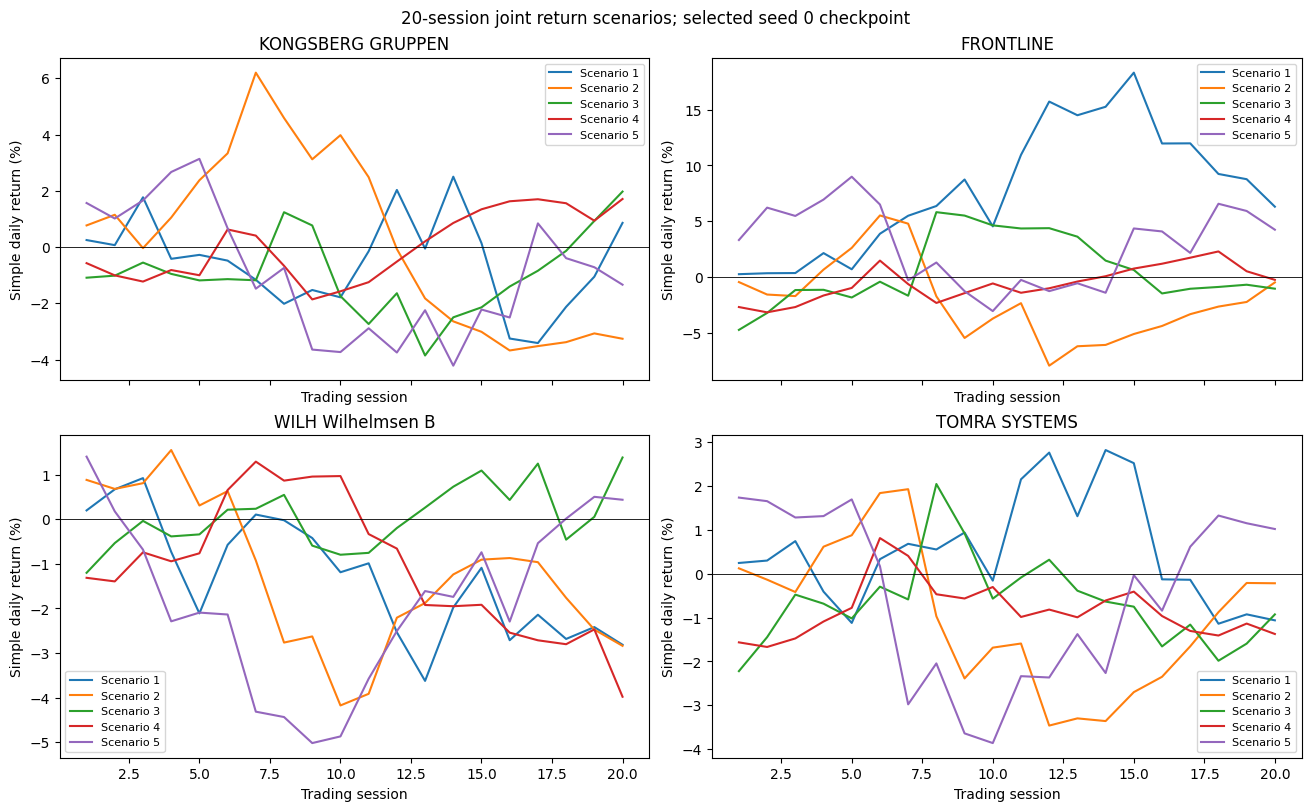

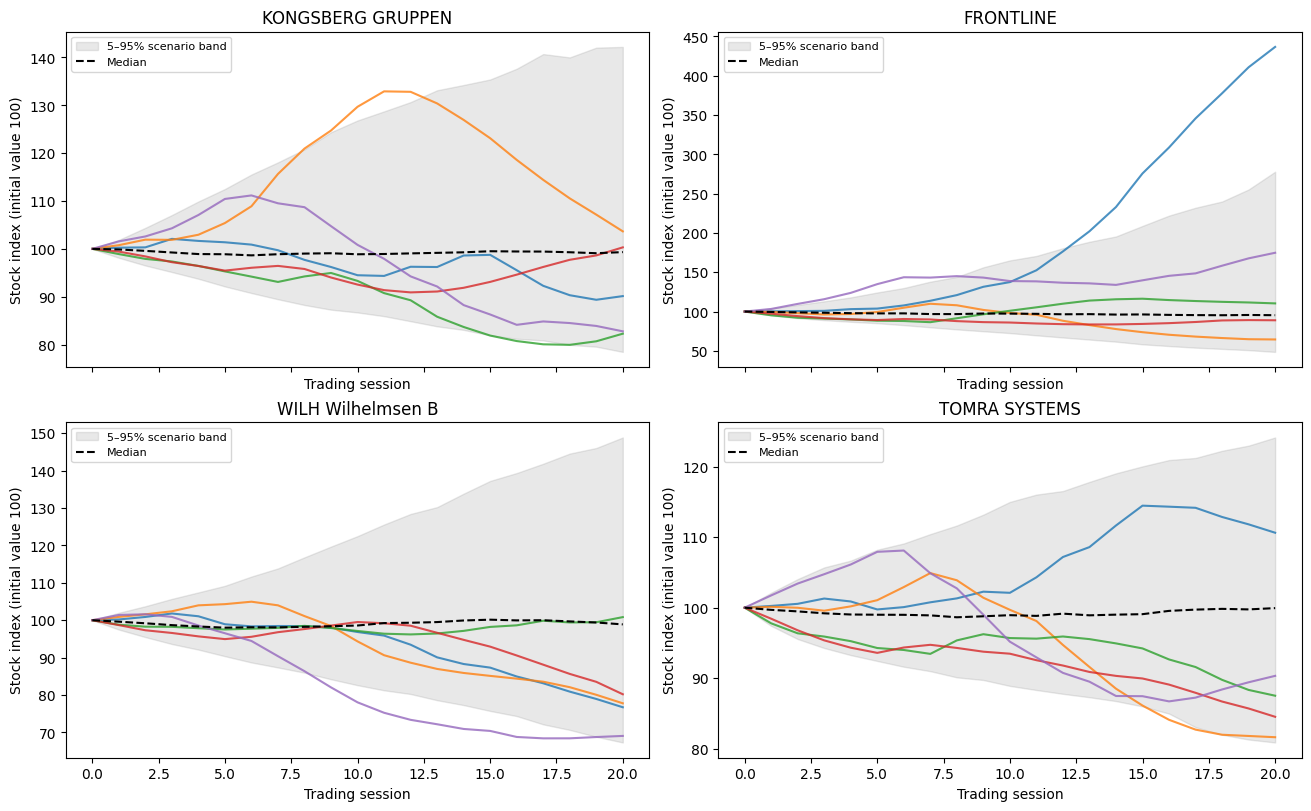

Tables, samples, settings, and plots saved to /Users/pasha/Desktop/master/master_thesis/sandbox/4stocks_experiment/results/sde_gan/inspection


In [7]:
scenario_returns = coarse_simple[PLOT_SEED]
HORIZON = scenario_returns.shape[1]
sessions = np.arange(1, HORIZON + 1)
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, constrained_layout=True)
for j, ax in enumerate(axes.flat):
    for i in range(5):
        ax.plot(sessions, scenario_returns[i, :, j] * 100, label=f"Scenario {i + 1}")
    ax.axhline(0, color="black", linewidth=0.6)
    ax.set(title=STOCKS[j], xlabel="Trading session", ylabel="Simple daily return (%)")
    ax.legend(fontsize=8)
fig.suptitle(f"{HORIZON}-session joint return scenarios; selected seed {PLOT_SEED} checkpoint")
fig.savefig(out_dir / "generated_returns.png", dpi=150)
plt.show()
plt.close(fig)
indexed = 100 * np.concatenate([np.ones((len(scenario_returns), 1, 4)),
                               np.cumprod(1 + scenario_returns, axis=1)], axis=1)
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, constrained_layout=True)
for j, ax in enumerate(axes.flat):
    lo, mid, hi = np.quantile(indexed[:, :, j], [0.05, 0.5, 0.95], axis=0)
    ax.fill_between(np.arange(HORIZON + 1), lo, hi, alpha=0.18, color="grey", label="5–95% scenario band")
    for i in range(5):
        ax.plot(np.arange(HORIZON + 1), indexed[i, :, j], alpha=0.8)
    ax.plot(np.arange(HORIZON + 1), mid, color="black", linestyle="--", label="Median")
    ax.set(title=STOCKS[j], xlabel="Trading session", ylabel="Stock index (initial value 100)")
    ax.legend(fontsize=8)
fig.savefig(out_dir / "generated_stock_indices.png", dpi=150)
plt.show()
plt.close(fig)
np.savez_compressed(out_dir / "illustrated_scenarios.npz", simple_returns=scenario_returns,
                    indexed_stock_paths=indexed)
(out_dir / "inspection.json").write_text(json.dumps({
    "run_seeds": RUN_SEEDS, "plot_seed": PLOT_SEED, "sample_seed": SAMPLE_SEED,
    "n_paths": N_PATHS, "horizon": HORIZON, "coarse_dt": COARSE_DT, "fine_dt": FINE_DT,
    "bootstrap_repeats": BOOTSTRAP_REPEATS, "bootstrap_seed": BOOTSTRAP_SEED,
    "stock_order": STOCKS, "preprocessing": reference_metadata,
}, indent=2, allow_nan=False) + "\n")
print(f"Tables, samples, settings, and plots saved to {out_dir}")